### INTEGRACIÓN NUMÉRICA

In [99]:
#Este ejercicio preparatorio busca que usted implemente correctamente tres métodos de integración numérica. Pruebe distintos valores de h. Si termina el ejercicio antes de que acabe la clase, repita el proceso para el método de Monte Carlo y el método del valor medio.

import numpy as np
import matplotlib.pylab as plt

# Función a integrar
def funcion(x1):
			return np.cos(x1)


In [100]:
#El intervalo de integración es de 0 a 3pi/2.
#Divida el intervalo de integración en M secciones para calcular sus integrales.
#pruebe distintos valores de M

# paso 1: use linespace (ver documentación: https://numpy.org/doc/stable/reference/generated/numpy.linspace.html)
# para hacer el arreglo de su intervalo en x
M=9999
a=0
b=3*np.pi/2
h = ( b - a ) / (M - 1)

#paso 2: genere el arreglo de valores de su función fx:

x = np.linspace(a, b, M)
f_x = funcion(x)

# Se puede sacar h de la operación, y se disminuye de 2N operaciones a N+1 operaciones
I_rec = h * np.sum(f_x)

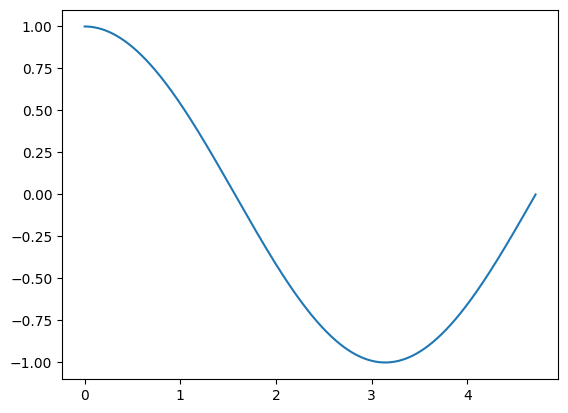

In [101]:
#1) grafique su función para verificar que hizo bien los pasos anteriores


import matplotlib.pyplot as plt

#plt.plot(x,fx)

plt.plot(x,f_x)
plt.show()

In [102]:
# 2a). Usando el método de suma de rectángulos, calcule la integral de la función.
#Compare su valor obtenido numéricamente con el valor analitico e imprima ambos valores.

x = np.linspace(a, b, M)
f_rec = funcion(x)
I_rec = h * np.sum(f_rec)

# Solución analítica: Sin(x)
Al_sin = np.sin(b)

# Comparación:
dif_rec = Al_sin - I_rec

print(f"Por suma de rectángulos la integral es: {I_rec}")
print(f"Mediante la solución analítica se espera: {Al_sin}")

print(f"La diferencia es: {dif_rec}")

Por suma de rectángulos la integral es: -0.9997643149047516
Mediante la solución analítica se espera: -1.0
La diferencia es: -0.00023568509524840575


In [103]:
# 2b). Usando el método de trapezoide, calcule la integral de la función.
#Compare su valor obtenido numéricamente con el valor analitico e imprima ambos valores.

x = np.linspace(a, b, M)
f_trap = funcion(x)

I_trap = h * np.sum(f_trap[1:-1])
I_trap += h/2 * (f_trap[0] + f_trap[-1])

# Solución analítica: Sin(x)
Al_sin = np.sin(b)

# Comparación:
dif_trap = Al_sin - I_trap

print(f"Por el método del trapezoide la integral es: {I_trap}")
print(f"Mediante la solución analítica se espera: {Al_sin}")

print(f"La diferencia es: {dif_trap}")

Por el método del trapezoide la integral es: -0.9999999814870874
Mediante la solución analítica se espera: -1.0
La diferencia es: -1.8512912647317137e-08


In [104]:
# 2c). Usando el método de Simpson, calcule la integral de la función.
#Compare su valor obtenido numéricamente con el valor analitico e imprima ambos valores.

x = np.linspace(a, b, M)
f_Simp = funcion(x)

I_Simp = 4*h/3 * np.sum(f_Simp[1:-1:2])
I_Simp += 2*h/3 * np.sum(f_Simp[2:-1:2])
I_Simp += h/3 * (f_Simp[0] + f_Simp[-1])

# Solución analítica: Sin(x)
Al_sin = np.sin(b)

# Comparación:
dif_Simp = Al_sin - I_Simp

print(f"Por el método de Simpson la integral es: {I_Simp}")
print(f"Mediante la solución analítica se espera: {Al_sin}")

print(f"La diferencia es: {dif_Simp}")

Por el método de Simpson la integral es: -1.0000000000000004
Mediante la solución analítica se espera: -1.0
La diferencia es: 4.440892098500626e-16


In [105]:
# 3a)Repita el ejercicio anterior usando algunos de los métodos de las librerías de scipy
# https://docs.scipy.org/doc/scipy/tutorial/integrate.html

from scipy.integrate import quad

I_SciPy = quad(funcion, a, b)
print(f"Mediante el método integrate.quad de la librería SciPy se obtuvo: {I_SciPy[0]} \n con una incertidumbre de {I_SciPy[1]}")

Mediante el método integrate.quad de la librería SciPy se obtuvo: -1.0000000000000002 
 con una incertidumbre de 3.334366076909448e-14


In [106]:
# 3b) Repita el ejercicio anterior usando el método de Monte Carlo y/o el del valor medio (ver diapositivas)

El resultado de la integral mediante montecarlo es: -1.0707618525286544



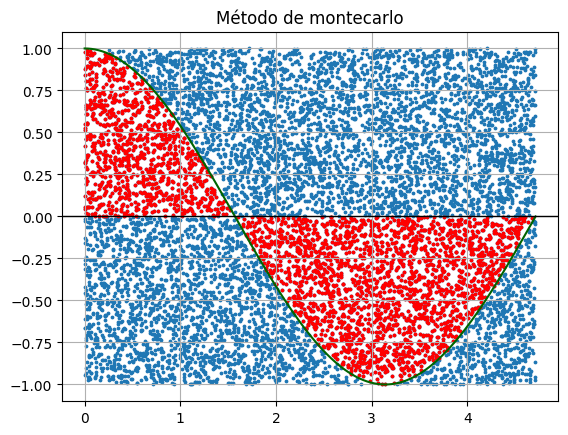

In [107]:
# La función de random.rand la obtuve de:
# https://www.w3schools.com/python/numpy/numpy_random.asp

x = np.linspace(a, b, M)
f_MC = funcion(x)

area_total = 2*b
contador = 0

x_MC = b * np.random.rand(M)
y_MC = 2 * np.random.rand(M) - 1  #El por dos es para que tome valores de 0 a 2, y le resto uno para que sea de -1 a 1

# Lo siguiente no logré encontrar como hacerlo sin lista, ya que el tamaño de puntos varía aleatoriamente sin semilla.

x_rojo = []
y_rojo = []

for i in range(M):
  F = funcion(x_MC[i])
  if(y_MC[i] < F and y_MC[i] > 0):
    x_rojo.append(x_MC[i])
    y_rojo.append(y_MC[i])
    contador += 1
  # Este segundo condicional es para contar puntos por debajo del eje x, por lo tanto resta al conteo.
  elif(y_MC[i] > F and y_MC[i] < 0):
    x_rojo.append(x_MC[i])
    y_rojo.append(y_MC[i])
    contador += -1

area_bajo_curva = (contador / M) * area_total

print(f"El resultado de la integral mediante montecarlo es: {area_bajo_curva}\n")

plt.scatter(x_MC, y_MC, s=3)
plt.scatter(x_rojo, y_rojo, s=3, color = "red") # Dibuja de color rojo los puntos que cayeron dentro de la curva
plt.plot(x, f_MC, color="darkgreen")
plt.axhline(color="black", linewidth=1)
plt.title("Método de montecarlo")
plt.grid(True)
plt.show()

---
Ejercicio 4 (opcional)

---

In [108]:
# 4 (OPCIONAL): Repita el procedimento anterior para distintos valores de M y,
#para cada metodo, haga una grafica del error en función de M. Guarde sus graficas en pdf.

M_lista = [9, 99, 999, 9999, 99999, 999999]
Sol_analitica = np.sin(b)

En la suma de rectángulos el error disminuye aproximadamente un orden de magnitud a medida que se aumenta un orden de magnitud el M.

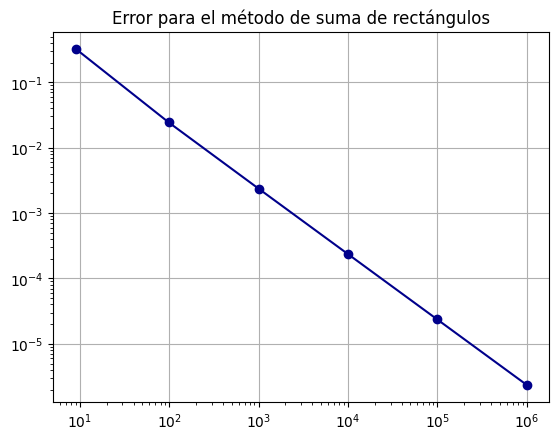

In [109]:
# Suma de rectángulos
Err_rec = np.zeros(6)
for rec in range(6):
  x = np.linspace(a, b, M_lista[rec])
  h = ( b - a ) / (M_lista[rec] - 1)
  f_rec = funcion(x)
  I_rec = h * np.sum(f_rec)

  Err_rec[rec] += np.abs(Sol_analitica - I_rec)

plt.loglog(M_lista, Err_rec, "-o", color="darkblue")
plt.title("Error para el método de suma de rectángulos")
plt.grid(True)
plt.show()

Para el método del trapecio el resultado fue similar a la suma de rectángulos, pero el error disminuye aproximadamente dos ordenes de magnitud por cada orden de magnitud que aumenta M.

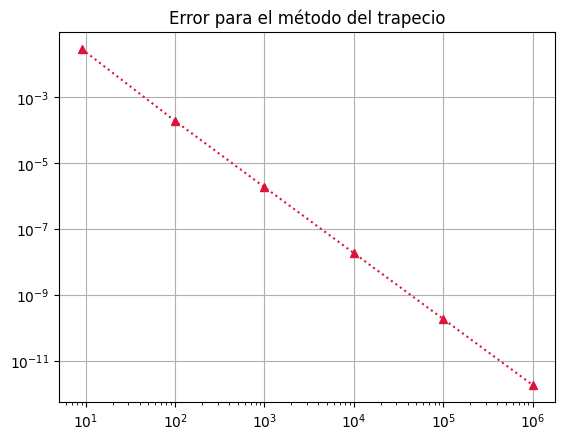

In [115]:
# Método del trapezoide
Err_tra = np.zeros(6)
for tra in range(6):
  x = np.linspace(a, b, M_lista[tra])
  h = ( b - a ) / (M_lista[tra] - 1)
  f_trap = funcion(x)

  I_trap = h * np.sum(f_trap[1:-1])
  I_trap += h/2 * (f_trap[0] + f_trap[-1])

  Err_tra[tra] += np.abs(Sol_analitica - I_trap)

plt.loglog(M_lista, Err_tra, ":^",color="crimson")
plt.title("Error para el método del trapecio")
plt.grid(True)
plt.show()

El método de simpson tiene aún menor error y este disminuye a unos cuatro ordenes de magnitud por cada orden de magnitud que aumenta el M. En la gráfica se pierde el valor para M = 99 999 ya que es prácticamente cero el error, e igualmente en M = 999 999 el error sube ya por el manejo de valores tan pequeños.

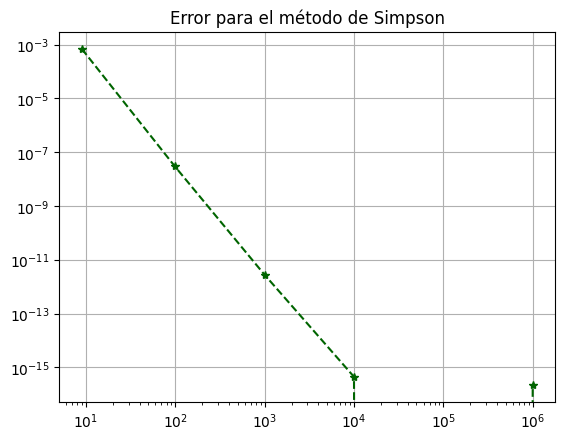

In [111]:
# Método de simpson
Err_sim = np.zeros(6)
for sim in range(6):
  x = np.linspace(a, b, M_lista[sim])
  h = ( b - a ) / (M_lista[sim] - 1)
  f_Simp = funcion(x)

  I_Simp = 4*h/3 * np.sum(f_Simp[1:-1:2])
  I_Simp += 2*h/3 * np.sum(f_Simp[2:-1:2])
  I_Simp += h/3 * (f_Simp[0] + f_Simp[-1])

  Err_sim[sim] += np.abs(Sol_analitica - I_Simp)

plt.loglog(M_lista, Err_sim, "--*",color="darkgreen")
plt.title("Error para el método de Simpson")
plt.grid(True)
plt.show()

Finalmente, el método de Montecarlo no es consistente en la relación de órdenes de magnitud debido a la aleatoriedad intrínseca, pero al ejecutar varias veces se observa que el error tiende a disminuir a mayor sea el valor de M.

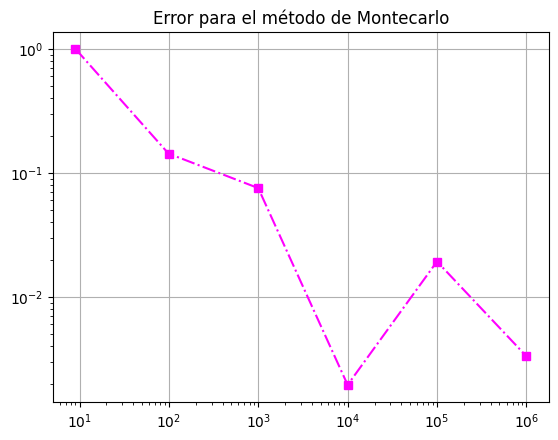

In [118]:
# Método de montecarlo
Err_MC = np.zeros(6)
for MC in range(6):
  x = np.linspace(a, b, M_lista[MC])
  h = ( b - a ) / (M_lista[MC] - 1)
  f_MC = funcion(x)

  area_total = 2*b
  contador = 0

  x_MC = b * np.random.rand(M_lista[MC])
  y_MC = 2 * np.random.rand(M_lista[MC]) - 1  #El por dos es para que tome valores de 0 a 2, y le resto uno para que sea de -1 a 1

  for i in range(M_lista[MC]):
    F = funcion(x_MC[i])
    if(y_MC[i] < F and y_MC[i] > 0):
      contador += 1
    # Este segundo condicional es para contar puntos por debajo del eje x, por lo tanto resta al conteo.
    elif(y_MC[i] > F and y_MC[i] < 0):
      contador += -1

  area_bajo_curva = (contador / M_lista[MC]) * area_total

  Err_MC[MC] += np.abs(Sol_analitica - area_bajo_curva)

plt.loglog(M_lista, Err_MC, "-.s",color="magenta")
plt.title("Error para el método de Montecarlo")
plt.grid(True)
plt.show()